# B2. Pembentukan Citra dan Ruang Warna
Mencakup lembar hitung 2.1 (verifikasi kode), rencana akuisisi, Kontras Bercak (KB) per kanal, sampling-kuantisasi, dan KB per kondisi cahaya.

In [1]:
# ===== Identitas dan lingkungan (jalankan paling awal) =====
import os, sys
NAMA, NIM, KELAS = "Hisham", "2330511007", "7A"      # ganti KELAS sesuai kelas Anda
SEED = int(NIM[-4:])                                   # 4 digit terakhir NIM -> 1007

try:                                                   # di Colab: simpan kerja di Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = f"/content/drive/MyDrive/simuteh-{NIM}"
except ImportError:                                    # di komputer sendiri
    cwd = os.getcwd()
    ROOT = os.path.dirname(cwd) if os.path.basename(cwd) == "notebook" else os.path.abspath(f"simuteh-{NIM}")

for sub in ["notebook", "src", "hasil", "laporan"]:
    os.makedirs(f"{ROOT}/{sub}", exist_ok=True)
os.chdir(f"{ROOT}/notebook")
print("Folder kerja:", os.getcwd(), "| SEED =", SEED)

Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/simuteh-2330511007/notebook | SEED = 1007


In [2]:
# ===== Impor pustaka dan fungsi bantu =====
sys.path.append("../src")
import time, json
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from utils_cv import baca, tampil, kontras_bercak, statistik
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    """Mengembalikan (citra, mask_daun, mask_bercak) untuk satu berkas."""
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

## Langkah 2.1: verifikasi lembar hitung


In [3]:
f_mm, piksel_mm, X = 4.0, 0.0014, 5.0         # panjang fokus, ukuran piksel sensor, diameter bercak (mm)
LEBAR_ASLI, TINGGI_ASLI, LEBAR_KERJA = 4000, 3000, 640

def ukuran_px(Z, skala=1.0):
    x_mm = f_mm * X / Z                       # x = f X / Z
    return x_mm, x_mm / piksel_mm * skala

for huruf, Z in [("a", 300), ("b", 600)]:
    x, p = ukuran_px(Z)
    print(f"{huruf}) Z={Z} mm -> bayangan {x:.4f} mm = {p:.1f} piksel")

Zmaks = f_mm * X / (10 * piksel_mm)
print(f"c) Z maksimum agar bercak >= 10 piksel: {Zmaks:.0f} mm ({Zmaks/10:.0f} cm)")

skala = LEBAR_KERJA / LEBAR_ASLI
_, p_kecil = ukuran_px(300, skala)
Zmaks_kecil = f_mm * X * skala / (10 * piksel_mm)
print(f"d) skala {skala}: diameter {p_kecil:.1f} piksel; Z maksimum >= 10 px: {Zmaks_kecil:.0f} mm ({Zmaks_kecil/10:.1f} cm)")

asli = LEBAR_ASLI * TINGGI_ASLI * 3
warna_kecil, abu_kecil = 640 * 480 * 3, 640 * 480
print(f"e) foto asli {asli/1e6:.1f} MB | 640x480 warna {warna_kecil/1e3:.1f} KB | keabuan {abu_kecil/1e3:.1f} KB | 300 foto {300*asli/1e9:.2f} GB")

bercak_rgb, daun_rgb = (196, 178, 86), (52, 136, 60)
Y = lambda r, g, b: 0.299 * r + 0.587 * g + 0.114 * b
print(f"f) Y bercak = {Y(*bercak_rgb):.1f}, Y daun = {Y(*daun_rgb):.1f}, selisih = {abs(Y(*bercak_rgb)-Y(*daun_rgb)):.1f}")
cek = np.array([[bercak_rgb[::-1], daun_rgb[::-1]]], np.uint8)            # RGB -> BGR untuk OpenCV
print("   cv2 Gray:", cv2.cvtColor(cek, cv2.COLOR_BGR2GRAY)[0], "| Hue OpenCV (0-179):", cv2.cvtColor(cek, cv2.COLOR_BGR2HSV)[0, :, 0])

a) Z=300 mm -> bayangan 0.0667 mm = 47.6 piksel
b) Z=600 mm -> bayangan 0.0333 mm = 23.8 piksel
c) Z maksimum agar bercak >= 10 piksel: 1429 mm (143 cm)
d) skala 0.16: diameter 7.6 piksel; Z maksimum >= 10 px: 229 mm (22.9 cm)
e) foto asli 36.0 MB | 640x480 warna 921.6 KB | keabuan 307.2 KB | 300 foto 10.80 GB
f) Y bercak = 172.9, Y daun = 102.2, selisih = 70.7
   cv2 Gray: [173 102] | Hue OpenCV (0-179): [25 63]


## Langkah 2.2: rencana akuisisi citra
*Draf, sesuaikan angkanya dengan hasil sel di atas.*

In [4]:
rencana = pd.DataFrame([
 ["Jarak dan sudut",   f"Tegak lurus dari atas, jarak <= {Zmaks_kecil/10:.0f} cm agar bercak 5 mm tetap >= 10 piksel pada lebar kerja 640 px"],
 ["Resolusi minimum",  "Foto asli >= 12 MP (4000 x 3000), diperkecil ke lebar 640 px sebelum diproses"],
 ["Alas dan acuan ukuran", "Nampan polos berwarna pucat; letakkan penggaris atau koin sebagai acuan skala"],
 ["Kondisi cahaya",    "Wakili normal, gelap, terang, kontras rendah (berkabut), dan bayangan sebagian"],
 ["Jumlah citra",      "Minimal 20 citra per kelas (Sehat, Ringan, Berat), tersebar merata pada kondisi cahaya"],
 ["Penamaan berkas",   "teh_<nomor 3 digit>.png; catat kondisi cahaya dan tanggal pada label.csv"],
 ["Izin dan privasi",  "Izin tertulis pemilik kebun; hapus metadata EXIF; foto tidak boleh memuat wajah"],
], columns=["Aspek", "Ketentuan"])
display(rencana); rencana.to_csv("../hasil/b2_rencana_akuisisi.csv", index=False)

,Aspek,Ketentuan
0,Jarak dan sudut,"Tegak lurus dari atas, jarak <= 23 cm agar ber..."
1,Resolusi minimum,"Foto asli >= 12 MP (4000 x 3000), diperkecil k..."
2,Alas dan acuan ukuran,Nampan polos berwarna pucat; letakkan penggari...
3,Kondisi cahaya,"Wakili normal, gelap, terang, kontras rendah (..."
4,Jumlah citra,"Minimal 20 citra per kelas (Sehat, Ringan, Ber..."
5,Penamaan berkas,teh_<nomor 3 digit>.png; catat kondisi cahaya ...
6,Izin dan privasi,Izin tertulis pemilik kebun; hapus metadata EX...


## Kode 2.1: pemisahan kanal dan KB (teh_041, berat, normal)

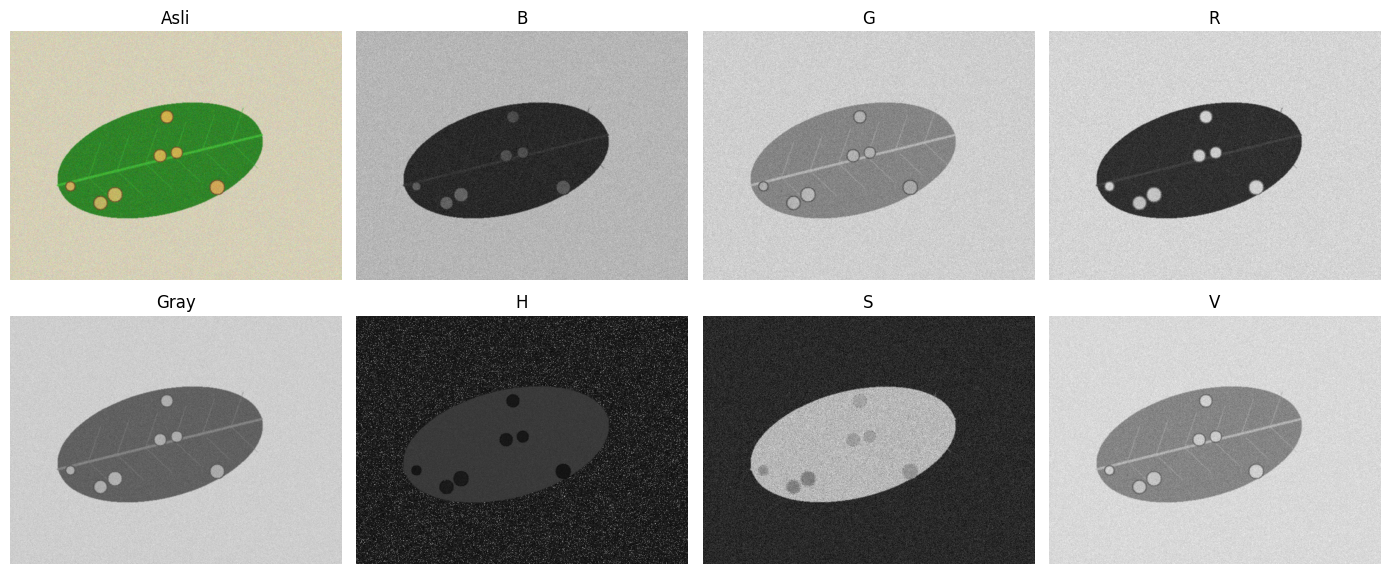

KB kanal B   : 2.70
KB kanal G   : 1.26
KB kanal R   : 9.73
KB kanal Gray: 5.20
KB kanal H   : 6.98
KB kanal S   : 1.73
KB kanal V   : 2.98


In [5]:
def semua_kanal(im):
    hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(im); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r, "Gray": cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), "H": h, "S": s, "V": v}

img, md, mb = muat("teh_041.png")
kn = semua_kanal(img)
tampil([img] + list(kn.values()), ["Asli"] + list(kn.keys()), baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_panel_kanal.png", dpi=110); plt.show()
for nm, c in kn.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

## Kode 2.2: sampling dan kuantisasi

,sampling,ukuran,KB
0,fx=0.5,320x240,6.26
1,fx=0.2,128x96,4.98
2,fx=0.1,64x48,3.40
3,fx=0.05,32x24,1.40


,bit,level,KB
0,1,2,5.13
1,2,3,5.17
2,3,6,3.00
3,4,11,4.64
4,8,172,5.20


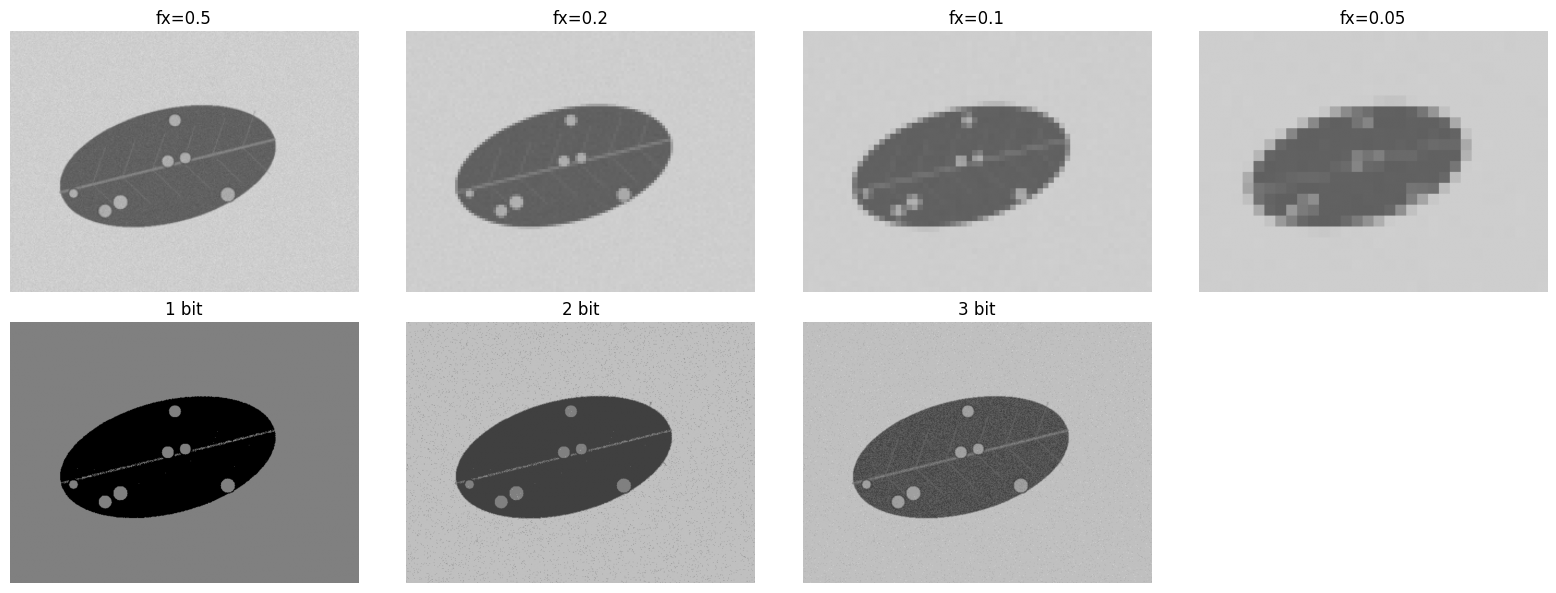

In [6]:
gray = kn["Gray"]
hs, citra_s = [], []
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    hs.append([f"fx={fx}", f"{kecil.shape[1]}x{kecil.shape[0]}", round(kontras_bercak(besar, md, mb), 2)]); citra_s.append(besar)
display(pd.DataFrame(hs, columns=["sampling", "ukuran", "KB"]))

hk, citra_k = [], []
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    hk.append([k, len(np.unique(kuant)), round(kontras_bercak(kuant, md, mb), 2)]); citra_k.append(kuant)
display(pd.DataFrame(hk, columns=["bit", "level", "KB"]))

tampil(citra_s + citra_k[:3], [f"fx={f}" for f in [0.5, 0.2, 0.1, 0.05]] + [f"{k} bit" for k in [1, 2, 3]], baris=2, ukuran=(16, 6))
plt.savefig("../hasil/b2_sampling_kuantisasi.png", dpi=110); plt.show()

## Kode 2.3 dan Langkah 2.6: rerata KB per kanal dan kondisi (berat dan ringan)

In [7]:
def tabel_kb(kelas):
    baris = []
    for _, d in label[label.kelas == kelas].iterrows():
        im, m_d, m_b = muat(d.nama_file)
        kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        kb["kondisi"] = d.kondisi_cahaya
        baris.append(kb)
    urutan = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
    return pd.DataFrame(baris).groupby("kondisi").mean().reindex(urutan).round(2)

kb_berat, kb_ringan = tabel_kb("berat"), tabel_kb("ringan")
print("Rerata KB kelas BERAT (Tabel 8)"); display(kb_berat)
print("Rerata KB ringan (Langkah 2.6)");    display(kb_ringan)
kb_berat.to_csv("../hasil/b2_kb_kanal.csv"); kb_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")
print("Kanal terbaik per kondisi (berat):", kb_berat.idxmax(axis=1).to_dict())
print("Rerata semua kondisi (berat):\n", kb_berat.mean().round(2).sort_values(ascending=False).to_dict())

Rerata KB kelas BERAT (Tabel 8)


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
normal,2.45,1.88,10.71,5.67,7.39,1.10,3.50
gelap,1.54,1.13,9.92,4.20,6.14,0.99,2.86
terang,1.76,0.27,8.14,3.65,7.29,0.99,1.60
kontras_rendah,0.88,0.43,4.13,2.18,2.36,0.24,1.44
bayangan,0.91,0.48,5.24,1.56,4.94,0.44,1.00


Rerata KB ringan (Langkah 2.6)


,B,G,R,Gray,H,S,V
kondisi,,,,,,,
normal,1.64,0.62,9.65,4.01,8.30,1.10,2.13
gelap,0.77,0.73,8.31,2.59,6.22,0.84,1.54
terang,1.28,0.80,7.04,2.39,7.32,1.41,0.37
kontras_rendah,0.67,0.26,3.66,1.79,2.04,0.31,1.12
bayangan,0.55,0.65,3.04,0.49,4.11,0.71,0.33


Kanal terbaik per kondisi (berat): {'normal': 'R', 'gelap': 'R', 'terang': 'R', 'kontras_rendah': 'R', 'bayangan': 'R'}
Rerata semua kondisi (berat):
 {'R': 7.63, 'H': 5.62, 'Gray': 3.45, 'V': 2.08, 'B': 1.51, 'G': 0.84, 'S': 0.75}


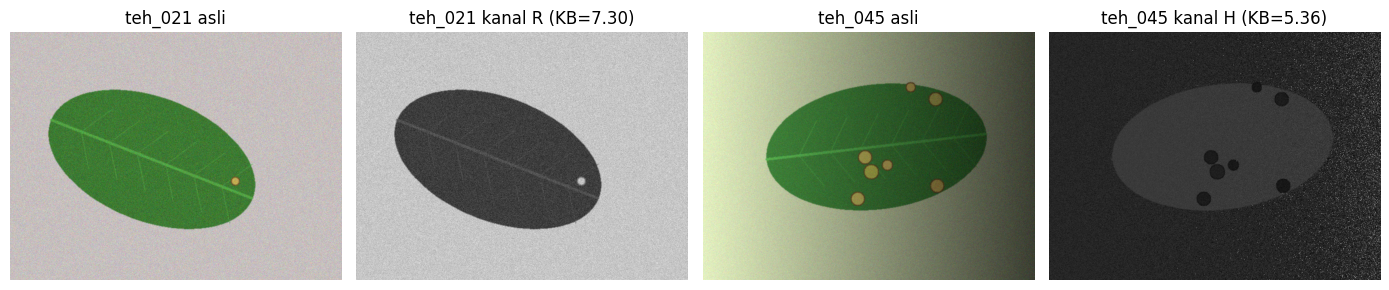

In [8]:
# Panel kanal terbaik: teh_021 (ringan, normal) dan teh_045 (berat, bayangan)
daftar, judul = [], []
for nm in ["teh_021.png", "teh_045.png"]:
    im, m_d, m_b = muat(nm); k_ = semua_kanal(im)
    terbaik = max(k_, key=lambda k: kontras_bercak(k_[k], m_d, m_b))
    daftar += [im, k_[terbaik]]
    judul += [f"{nm[:7]} asli", f"{nm[:7]} kanal {terbaik} (KB={kontras_bercak(k_[terbaik], m_d, m_b):.2f})"]
tampil(daftar, judul, ukuran=(14, 3.6)); plt.savefig("../hasil/b2_kanal_terbaik.png", dpi=110); plt.show()